[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_nlosc.ipynb)


# Nonlinear oscillations

## Nonlinear terms and averaging

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

For weakly nonlinear motion, retain the first anharmonic terms in the Taylor expansion of the Lagrangian. The amplitudes must remain small enough for the truncation to be useful, and the potential must confine the motion under consideration. In normal coordinates,

$$
L={L}^{\left(0\right)}+\frac{1}{2}\sum {\lambda }_{mns}{\dot{Q}}_{m}{\dot{Q}}_{n}{Q}_{s}-\frac{1}{3}\sum {\mu }_{mns}{Q}_{m}{Q}_{n}{Q}_{s}-\frac{1}{4}\sum {\mu }_{{k}_{1}{k}_{2}{k}_{3}{k}_{4}}{Q}_{{k}_{1}}{Q}_{{k}_{2}}{Q}_{{k}_{3}}{Q}_{{k}_{4}}\tag{1}
$$

where

$$
{L}^{\left(0\right)}=\frac{1}{2}{∑}_{i}\left({\dot{Q}}_{i}^{2}-{ω}_{i}^{2}{Q}_{i}^{2}\right)
$$

is the Lagrange function of harmonic approximation. Obviously, the EoM have the form

$$
\ddot{Q}+{\omega }_{i}^{2}Q=f\left(Q,\dot{Q},\ddot{Q}\right)\tag{2}
$$

with polynomial function f of 3d degree.  In such a situation one may try to find the solution by successive approximation method, i,e, searching the solution as 

$$
Q = {Q}^{\left(0\right)}+{Q}^{\left(1\right)}+{Q}^{\left(2\right)}+\ldots , \\ {Q}^{\left(0\right)}>>{Q}^{\left(1\right)}>>{Q}^{\left(2\right)}\ldots\tag{3}
$$

where, obviously, $ {Q}^{\left(0\right)}$ is unperturbed harmonic oscillations. Then

$$
{\ddot{Q}}_{i}^{\left(1\right)}+{\omega }_{i}^{2}{Q}_{i}^{\left(1\right)}={f}_{i}\left({Q}^{\left(0\right)},{\dot{Q}}^{\left(0\right)},{\ddot{Q}}^{\left(0\right)}\right)
$$

Products of harmonic terms generate overtones and combination frequencies. For a single mode, quadratic terms give a static shift and a second harmonic. In a multimode system they produce frequencies

$$
{\omega }_{i}\pm {\omega }_{j}, i,j=1,2,\ldots ,N
$$

For a single mode, cubic terms contain the fundamental and third harmonic. For several modes they produce combination frequencies

$$
{\omega }_{i}\pm {\omega }_{j}\pm {\omega }_{k}, i,j,k=1,2,\ldots ,N
$$

Among the latter there are ``resonance`` terms with frequencies ${\omega }_{i}$ of unperturbed system. Since we don’t have actual resonance in nonlinear system with unbounded amplitude we must conclude that actual frequencies ${\omega }_{i}$ shift from their unperturbed values ${\overset{o}{\omega }}_{i}$ of harmonic approximation so along with (3) we can write:

$$
{\omega }_{i}={\overset{o}{\omega }}_{i}+{\omega }_{i}^{\left(1\right)}+{\omega }_{i}^{\left(2\right)}+\ldots
$$

### Averaging: separating fast oscillation from slow evolution

The nonlinear terms above generate overtones and combination frequencies. A component at the fundamental frequency is resonant: its cumulative effect should be described by a slowly changing amplitude or phase, rather than by a correction that grows without bound. We now develop this idea for one mode with constant mass and a weak perturbation. Coupled modes near internal resonance require coupled slow equations and are outside the single-mode treatment below.

This exposition follows the supplied Physics 2400 notes, *Nonlinear oscillators. Method of averaging* (University of Connecticut, Spring 2017, revised 21 April 2017), especially Section 1, Section 3 and Problem 1. 

We scale time so the unperturbed angular frequency is one and use a single sign convention throughout:

$$
\ddot{x}+x=\varepsilon F\left(x,\dot{x}\right),    0<\varepsilon \ll 1.
$$

Smallness concerns the perturbation at the amplitudes being studied, not just the numerical value of its coefficient. For cubic stiffness or cubic damping with initial amplitude ${A}_{0}$, require $\varepsilon {A}_{0}^{2}\ll 1$.

### Why regular perturbation fails on a long time interval

Start with cubic velocity-dependent friction:

$$
\ddot{x}+x=-\varepsilon {\dot{x}}^{3},    x\left(0\right)=1,  \dot{x}\left(0\right)=0.
$$

Write $x={x}_{0}+\varepsilon {x}_{1}+\cdots $. At the first two orders,

$$
{\ddot{x}}_{0}+{x}_{0}=0,    {x}_{0}=cost,    {\ddot{x}}_{1}+{x}_{1}=\sin^{3}{t}.
$$

With zero initial displacement and velocity for the correction, the result is

$$
{x}_{1}=\frac{9}{32}sint+\frac{1}{32}\sin{3t}-\frac{3}{8}t cost.
$$

The last term is secular. Once $\varepsilon t$ is of order one, the expansion loses its ordering. It does not predict physical growth: the exact energy obeys

$$
E=\frac{{\dot{x}}^{2}+{x}^{2}}{2},    \dot{E}=-\varepsilon {\dot{x}}^{4}\le 0.
$$

Thus the exact motion remains bounded. The secular term is the short-time expansion of a decaying envelope. At higher perturbation orders, expand the complete cubic product: the forcing is not simply the cube of the preceding correction.

### Exact amplitude and phase equations

Away from the origin in the phase plane, introduce polar coordinates for the oscillator state:

$$
x=Acos\theta ,    v=\dot{x}=-Asin\theta ,    \theta =t+\psi .
$$

Here $A=\sqrt{{x}^{2}+{v}^{2}}$ and the phase is chosen continuously. These two equations define the variables exactly; they do not yet assume slow variation. Differentiating the first and imposing the second gives the auxiliary relation

$$
\dot{A}\cos{\theta} -A\dot{\psi }\sin{\theta} =0.
$$

Substitution into the equation for velocity gives

$$
-\dot{A}\sin{\theta} -A\dot{\psi }\cos{\theta} =\varepsilon F\left(Acos\theta ,-Asin\theta \right).
$$

Solving these two linear equations produces

$$
\dot{A}=-\varepsilon F\left(Acos\theta ,-Asin\theta \right)\sin{\theta} ,
$$

$$
\dot{\psi }=-\frac{\varepsilon }{A}F\left(Acos\theta ,-Asin\theta \right)\cos{\theta} .
$$

The amplitude equation also follows from $E={A}^{2}/2$ and $\dot{E}=\varepsilon vF$. Phase is undefined at $A=0$; the original state equations remain valid there.

### Averaging over one fast period

Freeze the slow amplitude and phase during one cycle. For any periodic expression $h$, define

$$
〈h〉=\frac{1}{2π}{\int }_{0}^{2π}h\left(φ\right) dφ.
$$

The first-order averaged equations are

$$
\dot{\overline{A}}=-\varepsilon 〈F\left(\overline{A}cosφ,-\overline{A}sinφ\right)sinφ〉,
$$

$$
\dot{\overline{\psi }}=-\frac{\varepsilon }{\overline{A}}〈F\left(\overline{A}cosφ,-\overline{A}sinφ\right)cosφ〉.
$$

Bars distinguish smooth averaged variables from the exact polar coordinates, which contain small fast oscillations. Reconstruct the leading state as

$$
{x}_{av}=\overline{A}\cos{\left(t+\overline{\psi }\right)},    {v}_{av}=-\overline{A}\sin{\left(t+\overline{\psi }\right)}.
$$

For a smooth weak perturbation on a suitable bounded domain, first-order averaging gives state errors of order $\varepsilon $ over times of order $1/\varepsilon $. It is not an exact solution or an unrestricted long-time guarantee. Differentiating the reconstructed displacement adds slow-derivative terms of order $\varepsilon $; consequently its derivative need not equal the independently reconstructed leading velocity to that order. Higher-order reconstruction resolves this difference.

For nonzero initial state, take $\overline{A}\left(0\right)=\sqrt{{x}_{0}^{2}+{v}_{0}^{2}}$ and choose $\overline{\psi }\left(0\right)$ from the two polar relations. Below, ${x}_{0}={A}_{0}>0$ and ${v}_{0}=0$, so the leading phase starts at zero.

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from IPython.display import display

avg_phi, avg_t = sp.symbols('phi t', real=True)
avg_A, avg_eps = sp.symbols('A epsilon', positive=True)
def phase_mean(expression):
    return sp.simplify(sp.integrate(expression, (avg_phi, 0, 2*sp.pi))/(2*sp.pi))

avg_x, avg_v = avg_A*sp.cos(avg_phi), -avg_A*sp.sin(avg_phi)
forcing_examples = {'Cubic damping': -avg_v**3,
                    'Duffing stiffness': -avg_x**3,
                    'Van der Pol (preview)': (1-avg_x**2)*avg_v}
averaged_rates = {}
for name, force in forcing_examples.items():
    rate_A = sp.factor(-avg_eps*phase_mean(force*sp.sin(avg_phi)))
    rate_phase = sp.simplify(-avg_eps*phase_mean(force*sp.cos(avg_phi))/avg_A)
    averaged_rates[name] = (rate_A, rate_phase)
    print(name, ': amplitude rate =', rate_A, '; phase rate =', rate_phase)
assert averaged_rates['Cubic damping'] == (-3*avg_eps*avg_A**3/8, 0)
assert averaged_rates['Duffing stiffness'] == (0, 3*avg_eps*avg_A**2/8)
avg_x1 = (9*sp.sin(avg_t)+sp.sin(3*avg_t))/32-3*avg_t*sp.cos(avg_t)/8
assert sp.trigsimp(sp.diff(avg_x1,avg_t,2)+avg_x1-sp.sin(avg_t)**3)==0
assert avg_x1.subs(avg_t,0)==sp.diff(avg_x1,avg_t).subs(avg_t,0)==0
display(sp.Eq(sp.Symbol('x_1'),avg_x1))

Cubic damping : amplitude rate = -3*A**3*epsilon/8 ; phase rate = 0
Duffing stiffness : amplitude rate = 0 ; phase rate = 3*A**2*epsilon/8
Van der Pol (preview) : amplitude rate = -A*epsilon*(A - 2)*(A + 2)/8 ; phase rate = 0


Eq(x_1, -3*t*cos(t)/8 + 9*sin(t)/32 + sin(3*t)/32)

### Example 1: cubic damping and an algebraically decaying envelope

For $F=-{v}^{3}$, the required averages are $〈\sin^{4} φ〉=3/8$ and $〈\sin^{3} φcosφ〉=0$. Therefore

$$
\dot{\overline{A}}=-\frac{3\varepsilon }{8}{\overline{A}}^{3},    \dot{\overline{\psi }}=0,    \overline{A}\left(t\right)=\frac{{A}_{0}}{\sqrt{1+3\varepsilon {A}_{0}^{2}t/4}}.
$$

Hence ${x}_{av}=\overline{A}\left(t\right)cost$ and ${E}_{av}={\overline{A}}^{2}/2$. The envelope decays algebraically rather than exponentially. Its expansion for ${A}_{0}=1$ begins with $1-3\varepsilon t/8$, explaining the secular contribution above. The exact instantaneous polar amplitude is $\sqrt{{x}^{2}+{v}^{2}}$; it need not equal the smooth envelope point by point.

The comparison uses $\varepsilon =0.1$, ${A}_{0}=1$ and identical leading initial state. The regular expansion is included to show its failure on the same long interval. All error values below are sampled maximum absolute differences, not rigorous bounds. Solver tolerances are much smaller than the approximation errors.

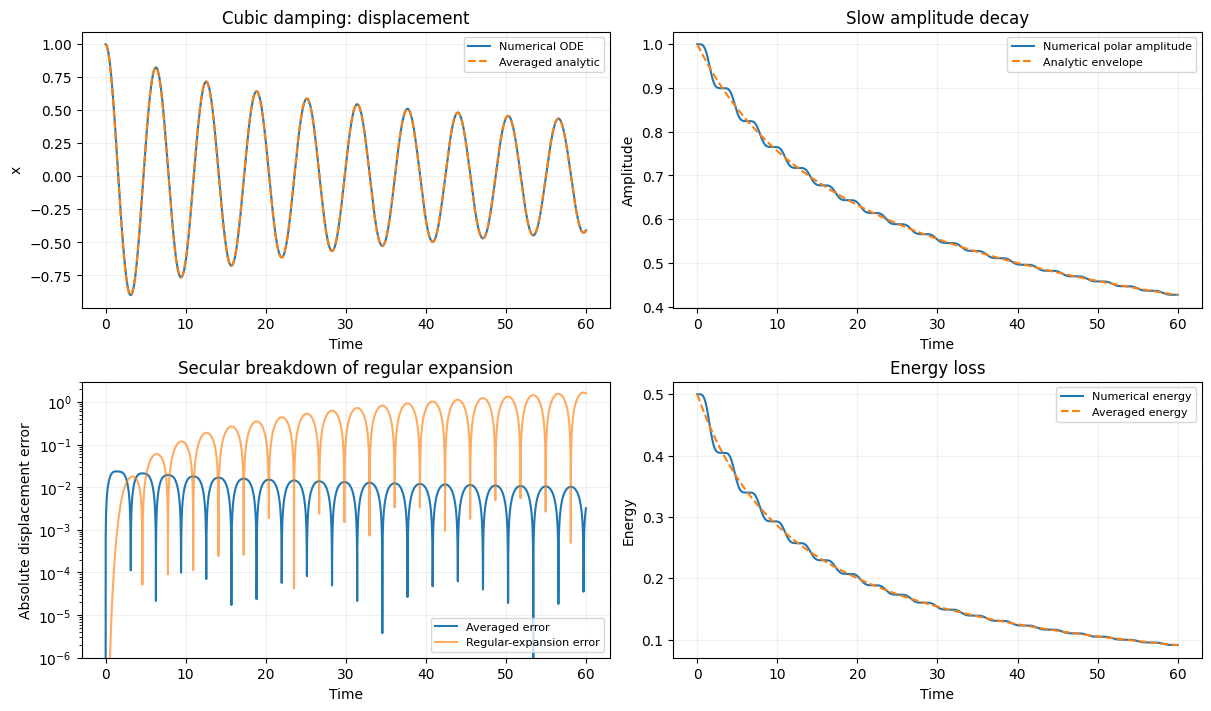

Maximum displacement error: averaged = 0.02358372999072611 ; regular expansion = 1.6655466601220592


In [3]:
def averaging_solve(force, epsilon, end, A0=1.0):
    def rhs(t, state):
        x, v = state
        return [v, -x+epsilon*force(x,v)]
    result = solve_ivp(rhs,(0,end),[A0,0],method='DOP853',rtol=1e-11,
                       atol=1e-13,max_step=0.05,dense_output=True)
    assert result.success, result.message
    return result

avg_epsilon, avg_A0, avg_end = 0.1, 1.0, 60.0
avg_times = np.linspace(0,avg_end,6001)
avg_damping_sol = averaging_solve(lambda x,v:-v**3,avg_epsilon,avg_end)
avg_num_x, avg_num_v = avg_damping_sol.sol(avg_times)
avg_envelope = avg_A0/np.sqrt(1+0.75*avg_epsilon*avg_A0**2*avg_times)
avg_damping_x = avg_envelope*np.cos(avg_times)
avg_regular_x = np.cos(avg_times)+avg_epsilon*((9*np.sin(avg_times)+np.sin(3*avg_times))/32-3*avg_times*np.cos(avg_times)/8)
fig,axes=plt.subplots(2,2,figsize=(12,7),layout='constrained')
axes[0,0].plot(avg_times,avg_num_x,label='Numerical ODE')
axes[0,0].plot(avg_times,avg_damping_x,'--',label='Averaged analytic')
axes[0,0].set(title='Cubic damping: displacement',ylabel='x')
axes[0,1].plot(avg_times,np.hypot(avg_num_x,avg_num_v),label='Numerical polar amplitude')
axes[0,1].plot(avg_times,avg_envelope,'--',label='Analytic envelope')
axes[0,1].set(title='Slow amplitude decay',ylabel='Amplitude')
axes[1,0].semilogy(avg_times,np.maximum(abs(avg_num_x-avg_damping_x),1e-14),label='Averaged error')
axes[1,0].semilogy(avg_times,np.maximum(abs(avg_num_x-avg_regular_x),1e-14),alpha=.65,label='Regular-expansion error')
axes[1,0].set(title='Secular breakdown of regular expansion',ylabel='Absolute displacement error',ylim=(1e-6,3))
axes[1,1].plot(avg_times,(avg_num_x**2+avg_num_v**2)/2,label='Numerical energy')
axes[1,1].plot(avg_times,avg_envelope**2/2,'--',label='Averaged energy')
axes[1,1].set(title='Energy loss',ylabel='Energy')
for ax in axes.flat: ax.set_xlabel('Time'); ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
print('Maximum displacement error: averaged =',float(np.max(abs(avg_num_x-avg_damping_x))),
      '; regular expansion =',float(np.max(abs(avg_num_x-avg_regular_x))))

### Example 2: Duffing stiffness and an amplitude-dependent frequency

For a conservative cubic restoring force,

$$
\ddot{x}+x+\varepsilon {x}^{3}=0,    F=-{x}^{3}.
$$

The averages $〈\cos^{3} φsinφ〉=0$ and $〈\cos^{4} φ〉=3/8$ yield

$$
\dot{\overline{A}}=0,    \dot{\overline{\psi }}=\frac{3\varepsilon {A}_{0}^{2}}{8},    {\Omega }_{av}=1+\frac{3\varepsilon {A}_{0}^{2}}{8}.
$$

$$
{x}_{av}\left(t\right)={A}_{0}\cos{\left({\Omega }_{av}t\right)}.
$$

Positive cubic stiffness raises the frequency (hardening). Averaging captures the cumulative phase shift, while the leading sinusoid omits small higher harmonics. For negative stiffness the local weak-amplitude shift is downward; the motion must still lie in the bounded region of the potential.

For the numerical comparison, the turning-point amplitude is ${A}_{0}=1$. We obtain an independent frequency from the exact energy integral, evaluated numerically:

$$
{T}_{energy}=4{\int }_{0}^{π/2}\frac{d\chi }{\sqrt{1+\varepsilon {A}_{0}^{2}\left(1+\sin^{2}{\chi} \right)/2}},    {\Omega }_{energy}=\frac{2π}{{T}_{energy}}.
$$

The polar radius $\sqrt{{x}^{2}+{v}^{2}}$ is not constant for the exact Duffing motion; conservation concerns the full energy ${v}^{2}/2+{x}^{2}/2+\varepsilon {x}^{4}/4$. The earlier quadratic-plus-cubic example has the small-amplitude frequency correction $\left(3b/8-5{a}^{2}/12\right){A}_{0}^{2}$ for $\ddot{x}+x+a{x}^{2}+b{x}^{3}=0$. First-order averaging alone does not produce the quadratic-force contribution: it arises at second perturbative order.

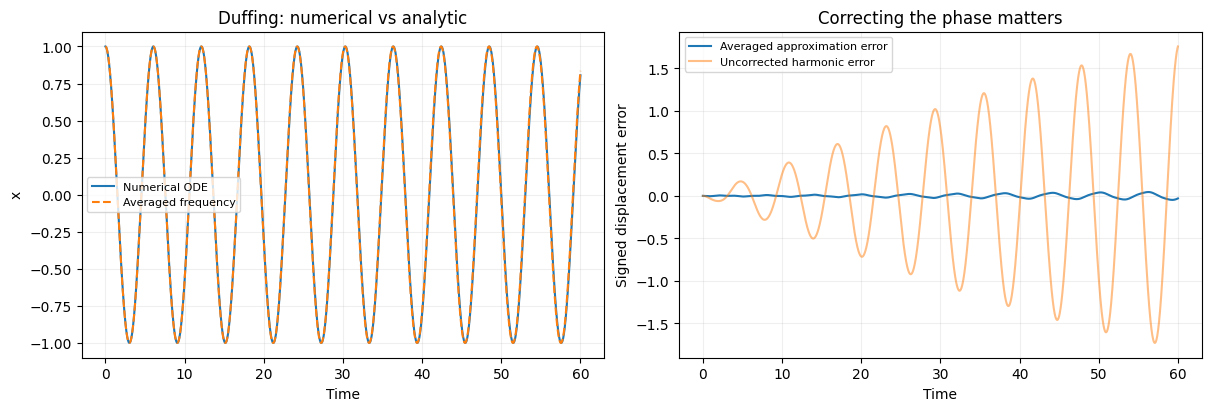

Averaged frequency: 1.0375000000
Energy-quadrature frequency: 1.0367169071
Maximum displacement error: 0.047485


In [4]:
avg_duffing_sol=averaging_solve(lambda x,v:-x**3,avg_epsilon,avg_end)
avg_duffing_num=avg_duffing_sol.sol(avg_times)[0]
avg_duffing_omega=1+3*avg_epsilon*avg_A0**2/8
avg_duffing_x=avg_A0*np.cos(avg_duffing_omega*avg_times)
avg_energy_period=4*quad(lambda chi:1/np.sqrt(1+avg_epsilon*avg_A0**2*(1+np.sin(chi)**2)/2),0,np.pi/2,
                         epsabs=1e-12,epsrel=1e-12)[0]
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].plot(avg_times,avg_duffing_num,label='Numerical ODE')
axes[0].plot(avg_times,avg_duffing_x,'--',label='Averaged frequency')
axes[0].set(xlabel='Time',ylabel='x',title='Duffing: numerical vs analytic')
axes[1].plot(avg_times,avg_duffing_num-avg_duffing_x,label='Averaged approximation error')
axes[1].plot(avg_times,avg_duffing_num-np.cos(avg_times),alpha=.5,label='Uncorrected harmonic error')
axes[1].set(xlabel='Time',ylabel='Signed displacement error',title='Correcting the phase matters')
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
print(f'Averaged frequency: {avg_duffing_omega:.10f}')
print(f'Energy-quadrature frequency: {2*np.pi/avg_energy_period:.10f}')
print(f'Maximum displacement error: {np.max(abs(avg_duffing_num-avg_duffing_x)):.6g}')

### Quantifying accuracy as the perturbation becomes smaller

Compare both models over the same slow-time interval $0\le \varepsilon t\le 6$. Thus each smaller $\varepsilon $ is tested for a longer physical time. The sampled maximum displacement error is

$$
{\mathcal{E} }_{x}={\text{max}}_{0\le t\le 6/\varepsilon }\left|{x}_{num}\left(t\right)-{x}_{av}\left(t\right)\right|.
$$

The table reports the integration interval and errors for cubic damping and Duffing stiffness. The logarithmic plot includes a first-order scaling guide. The values are empirical checks for these initial data, not a proof of the averaging theorem. A frequency error of second order can accumulate into a first-order displacement error over a time of order $1/\varepsilon $.

 epsilon   end time   max error: damping   max error: Duffing
   0.200       30.0           0.04476653           0.08574078
   0.100       60.0           0.02358373           0.04748501
   0.050      120.0           0.01212852           0.02443976
   0.025      240.0           0.00615432           0.01240412


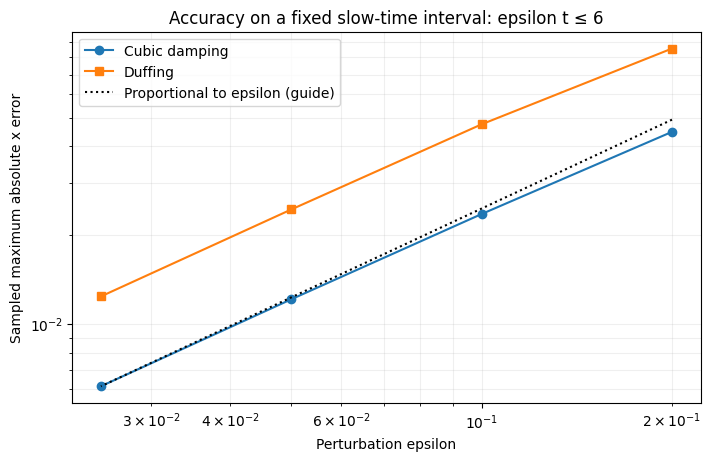

In [5]:
avg_convergence=[]
for eps_value in (0.2,0.1,0.05,0.025):
    end=6/eps_value
    times=np.linspace(0,end,int(end/0.01)+1)
    damping=averaging_solve(lambda x,v:-v**3,eps_value,end)
    duffing=averaging_solve(lambda x,v:-x**3,eps_value,end)
    damping_analytic=np.cos(times)/np.sqrt(1+0.75*eps_value*times)
    duffing_analytic=np.cos((1+3*eps_value/8)*times)
    errors=[np.max(abs(damping.sol(times)[0]-damping_analytic)),
            np.max(abs(duffing.sol(times)[0]-duffing_analytic))]
    avg_convergence.append([eps_value,end,*errors])
avg_convergence=np.array(avg_convergence)
print(' epsilon   end time   max error: damping   max error: Duffing')
for row in avg_convergence: print(f'{row[0]:8.3f} {row[1]:10.1f} {row[2]:20.8f} {row[3]:20.8f}')
fig,ax=plt.subplots(figsize=(7,4.5),layout='constrained')
ax.loglog(avg_convergence[:,0],avg_convergence[:,2],'o-',label='Cubic damping')
ax.loglog(avg_convergence[:,0],avg_convergence[:,3],'s-',label='Duffing')
ax.loglog(avg_convergence[:,0],avg_convergence[-1,2]*avg_convergence[:,0]/avg_convergence[-1,0],
          'k:',label='Proportional to epsilon (guide)')
ax.set(xlabel='Perturbation epsilon',ylabel='Sampled maximum absolute x error',
       title='Accuracy on a fixed slow-time interval: epsilon t ≤ 6')
ax.legend(); ax.grid(which='both',alpha=.2); plt.show()

### Example 3: slowly varying frequency and adiabatic invariance

The supplied notes also apply averaging to a linear oscillator with slowly changing parameters. This is a different mechanism from nonlinear stiffness, but it illustrates the same separation of time scales:

$$
\ddot{x}+{\omega }^{2}\left(t\right)x=0,    \omega \left(t\right)>0,    \frac{\left|\dot{\omega }\right|}{{\omega }^{2}}\ll 1.
$$

Introduce fast phase $\tau ={\int }_{0}^{t}\omega \left(s\right) ds$. Derivatives with respect to this phase are written explicitly to avoid confusing them with time derivatives:

$$
\frac{{d}^{2}x}{d{\tau }^{2}}+x=-\frac{\dot{\omega }}{{\omega }^{2}}\frac{dx}{d\tau }.
$$

Averaging this weak effective damping gives

$$
\frac{d\overline{A}}{d\tau }=-\frac{\dot{\omega }}{2{\omega }^{2}}\overline{A},    \frac{d\overline{A}}{dt}=-\frac{\dot{\omega }}{2\omega }\overline{A},    \overline{A}=\frac{C}{\sqrt{\omega }}.
$$

The leading displacement and adiabatic invariant are

$$
{x}_{av}\left(t\right)=\frac{C}{\sqrt{\omega \left(t\right)}}\cos{\left(\tau +{\psi }_{0}\right)},    I=\frac{E}{\omega }\approx \frac{{C}^{2}}{2},    E=\frac{{\dot{x}}^{2}+{\omega }^{2}{x}^{2}}{2}.
$$

Energy itself need not be constant: changing the stiffness does work. The statement about $E/\omega $ is approximate. This construction fails near a zero of $\omega $ or when the fractional change per period is not small.

For a comparison with matching displacement and derivative at the initial time, choose

$$
\omega \left(t\right)=1+0.3\left(1-\cos{\varepsilon} t\right),    \tau =1.3t-\frac{0.3}{\varepsilon }\sin{\varepsilon} t.
$$

Here $\dot{\omega }\left(0\right)=0$, so $C=1$, ${\psi }_{0}=0$ gives ${x}_{av}\left(0\right)=1$ and ${\dot{x}}_{av}\left(0\right)=0$. The plot compares the ODE solution and approximation, their error, and the numerical adiabatic invariant over one slow modulation cycle.

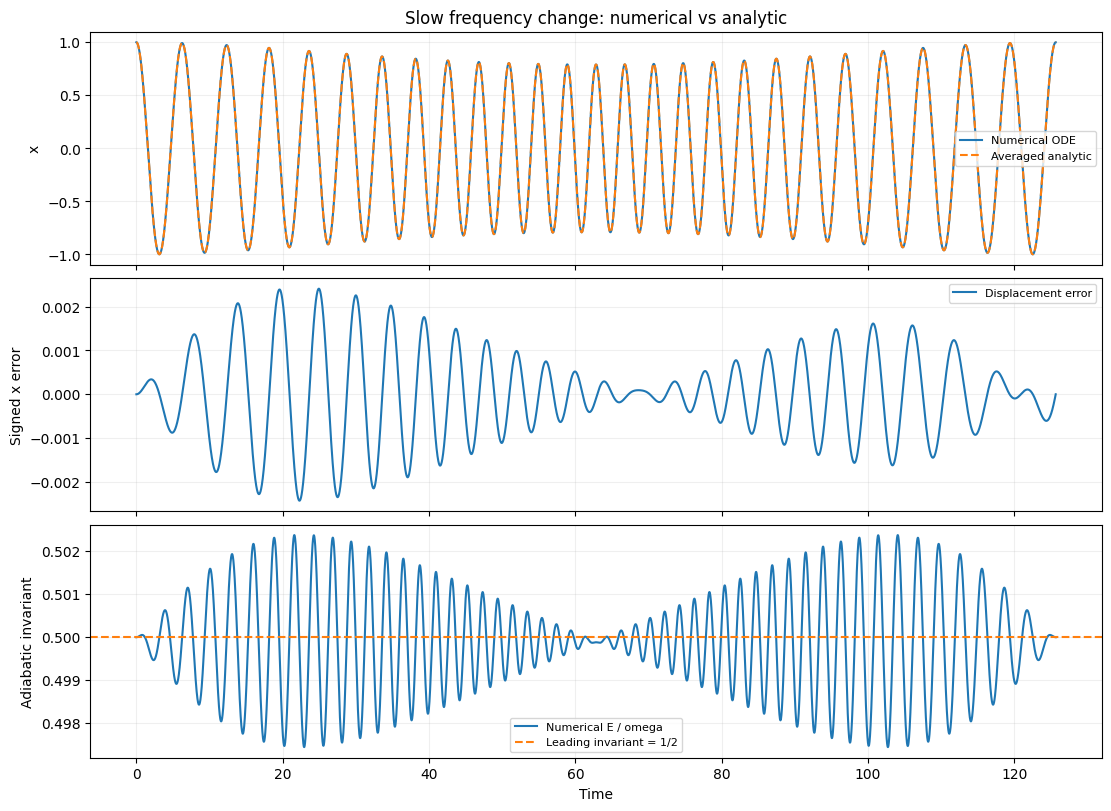

Maximum displacement error: 0.0024294319860006866
Maximum relative invariant variation: 0.005115691634024588


In [6]:
avg_adiabatic_eps=0.05
avg_adiabatic_end=2*np.pi/avg_adiabatic_eps
avg_adiabatic_times=np.linspace(0,avg_adiabatic_end,14001)
def avg_frequency(t): return 1+0.3*(1-np.cos(avg_adiabatic_eps*t))
def avg_fast_phase(t): return 1.3*t-0.3*np.sin(avg_adiabatic_eps*t)/avg_adiabatic_eps
avg_adiabatic_sol=solve_ivp(lambda t,z:[z[1],-avg_frequency(t)**2*z[0]],
                           (0,avg_adiabatic_end),[1,0],method='DOP853',
                           rtol=1e-11,atol=1e-13,max_step=0.05,dense_output=True)
assert avg_adiabatic_sol.success
avg_ad_x,avg_ad_v=avg_adiabatic_sol.sol(avg_adiabatic_times)
avg_om=avg_frequency(avg_adiabatic_times)
avg_ad_analytic=np.cos(avg_fast_phase(avg_adiabatic_times))/np.sqrt(avg_om)
avg_action=(avg_ad_v**2+avg_om**2*avg_ad_x**2)/(2*avg_om)
fig,axes=plt.subplots(3,1,figsize=(11,8),layout='constrained',sharex=True)
axes[0].plot(avg_adiabatic_times,avg_ad_x,label='Numerical ODE')
axes[0].plot(avg_adiabatic_times,avg_ad_analytic,'--',label='Averaged analytic')
axes[0].set(ylabel='x',title='Slow frequency change: numerical vs analytic')
axes[1].plot(avg_adiabatic_times,avg_ad_x-avg_ad_analytic,label='Displacement error')
axes[1].set_ylabel('Signed x error')
axes[2].plot(avg_adiabatic_times,avg_action,label='Numerical E / omega')
axes[2].axhline(.5,color='C1',ls='--',label='Leading invariant = 1/2')
axes[2].set(xlabel='Time',ylabel='Adiabatic invariant')
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
print('Maximum displacement error:',float(np.max(abs(avg_ad_x-avg_ad_analytic))))
print('Maximum relative invariant variation:',float(np.max(abs(avg_action/.5-1))))

### What the comparisons teach

Cubic damping changes the amplitude at leading order; Duffing stiffness changes the phase; a slowly varying linear frequency changes both the fast phase and the envelope. Averaging retains these accumulated effects and omits small fast corrections. A visually close waveform is only one check: inspect errors, energy or action, and convergence as the perturbation decreases.

1. Derive the exact amplitude and phase equations independently and check their signs using linear viscous damping.

2. For $F=-{v}^{5}$, use $〈\sin^{6} φ〉=5/16$ to derive the envelope and compare it with numerical integration.

3. Repeat the Duffing comparison for several initial amplitudes. Which dimensionless combination controls the approximation?

4. For dry friction during sliding, use $F=-sgnv$ to find the leading envelope. Explain why averaging fails near stopping and why a model of static friction is needed to describe sticking; simply assigning a single value to the force at zero velocity is insufficient.

5. Increase the modulation rate in the variable-frequency example. Track the error in the approximate invariant as well as the displacement error.

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)